# Resume Classification using NLP

Classifies resumes into job categories (Data Science, HR, Java Developer, Testing, …) using **TF-IDF** features and three machine learning models, then selects the best model using standard classification metrics.

**Steps:** Load data → Clean text → EDA → Encode labels → Train/test split → TF-IDF → Train models → Evaluate → Save best model → Predict.

## 1. Import libraries

In [4]:
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = Path("UpdatedResumeDataSet.csv")
IMAGES, MODELS = Path("images"), Path("models")
IMAGES.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

## 2. Load the data

In [6]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (962, 2)


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \n MCA YMCAUST, Faridabad..."


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  962 non-null    object
 1   Resume    962 non-null    object
dtypes: object(2)
memory usage: 15.2+ KB


In [8]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df[["Category", "Resume"]].dropna().drop_duplicates().reset_index(drop=True)
print(f"\nAfter cleaning: {len(df)} resumes across {df['Category'].nunique()} categories")

Missing values:
 Category    0
Resume      0
dtype: int64

Duplicate rows: 796

After cleaning: 166 resumes across 25 categories


## 3. Clean the resume text
Lowercase everything, then remove URLs, emails, hashtags, numbers, special characters and common stopwords (e.g. *the, and, is*), which carry no information about the category.

In [10]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"\S+@\S+", " ", text)             # emails
    text = re.sub(r"#\S+|@\S+", " ", text)           # hashtags / mentions
    text = re.sub(r"[^a-z\s]", " ", text)            # numbers, punctuation, non-ASCII
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1]
    return " ".join(words)

df["Cleaned"] = df["Resume"].apply(clean_text)
df["word_count"] = df["Cleaned"].str.split().str.len()

print("BEFORE:\n", df.loc[0, "Resume"][:300])
print("\nAFTER:\n", df.loc[0, "Cleaned"][:300])

BEFORE:
 Skills * Programming Languages: Python (pandas, numpy, scipy, scikit-learn, matplotlib), Sql, Java, JavaScript/JQuery. * Machine learning: Regression, SVM, NaÃ¯ve Bayes, KNN, Random Forest, Decision Trees, Boosting techniques, Cluster Analysis, Word Embedding, Sentiment Analysis, Natural Language pr

AFTER:
 skills programming languages python pandas numpy scipy scikit learn matplotlib sql java javascript jquery machine learning regression svm na ve bayes knn random forest decision trees boosting techniques cluster analysis word embedding sentiment analysis natural language processing dimensionality red


## 4. Exploratory Data Analysis
### 4.1 How many resumes are in each category?
Checks whether the classes are balanced. If some categories have very few resumes, accuracy alone can be misleading.

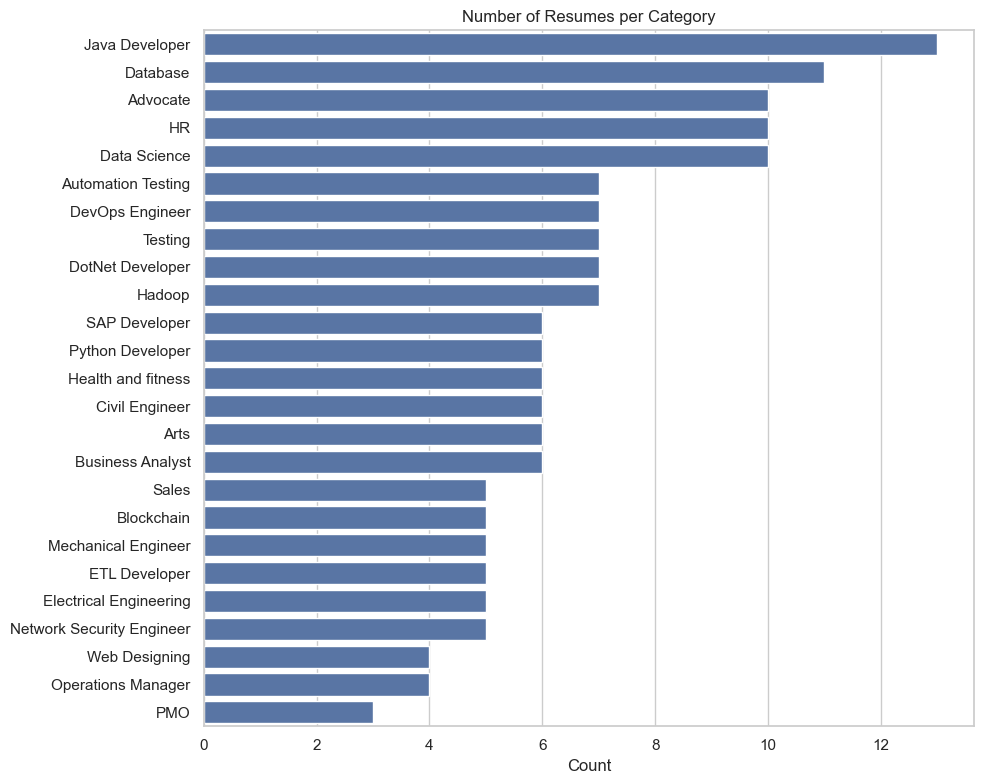

Category
Java Developer               13
Database                     11
Advocate                     10
HR                           10
Data Science                 10
Automation Testing            7
DevOps Engineer               7
Testing                       7
DotNet Developer              7
Hadoop                        7
SAP Developer                 6
Python Developer              6
Health and fitness            6
Civil Engineer                6
Arts                          6
Business Analyst              6
Sales                         5
Blockchain                    5
Mechanical Engineer           5
ETL Developer                 5
Electrical Engineering        5
Network Security Engineer     5
Web Designing                 4
Operations Manager            4
PMO                           3
Name: count, dtype: int64

In [12]:
order = df["Category"].value_counts().index
plt.figure(figsize=(10, 8))
sns.countplot(y="Category", data=df, order=order, color="#4C72B0")
plt.title("Number of Resumes per Category")
plt.xlabel("Count"); plt.ylabel("")
plt.tight_layout()
plt.savefig(IMAGES / "category_distribution.png", dpi=120)
plt.show()

df["Category"].value_counts()

### 4.2 Resume length by category

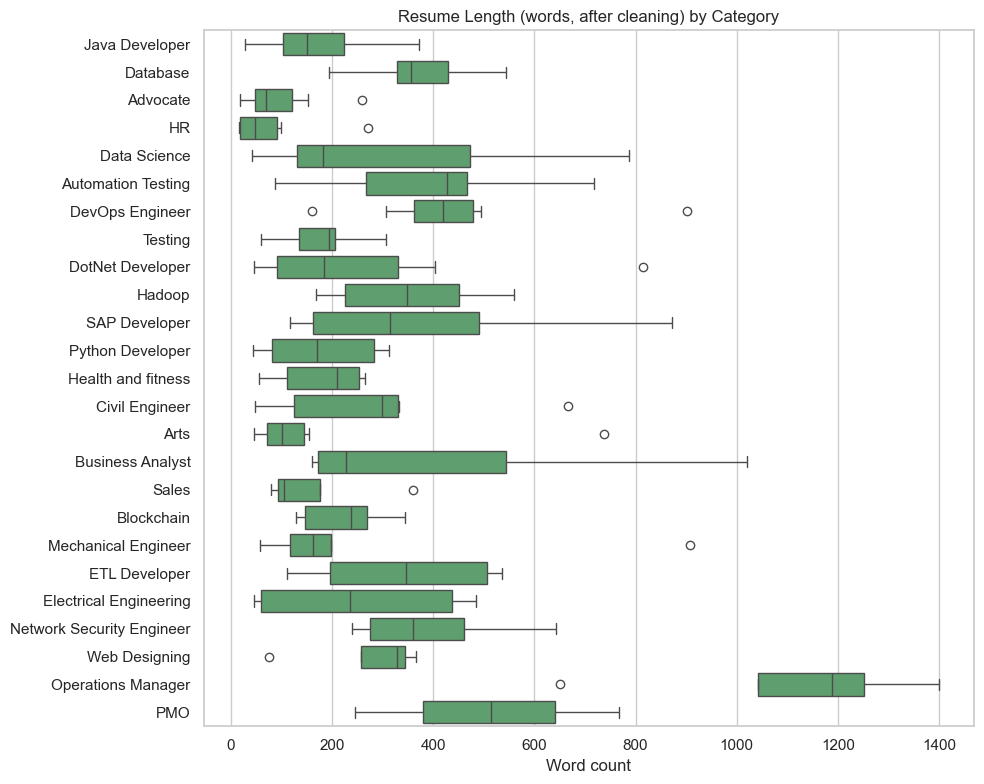

count     166.000000
mean      286.066265
std       248.357785
min        15.000000
25%       102.500000
50%       224.500000
75%       381.500000
max      1400.000000
Name: word_count, dtype: float64

In [14]:
plt.figure(figsize=(10, 8))
sns.boxplot(y="Category", x="word_count", data=df, order=order, color="#55A868")
plt.title("Resume Length (words, after cleaning) by Category")
plt.xlabel("Word count"); plt.ylabel("")
plt.tight_layout()
plt.savefig(IMAGES / "resume_length_by_category.png", dpi=120)
plt.show()

df["word_count"].describe()

### 4.3 Most common words in the dataset

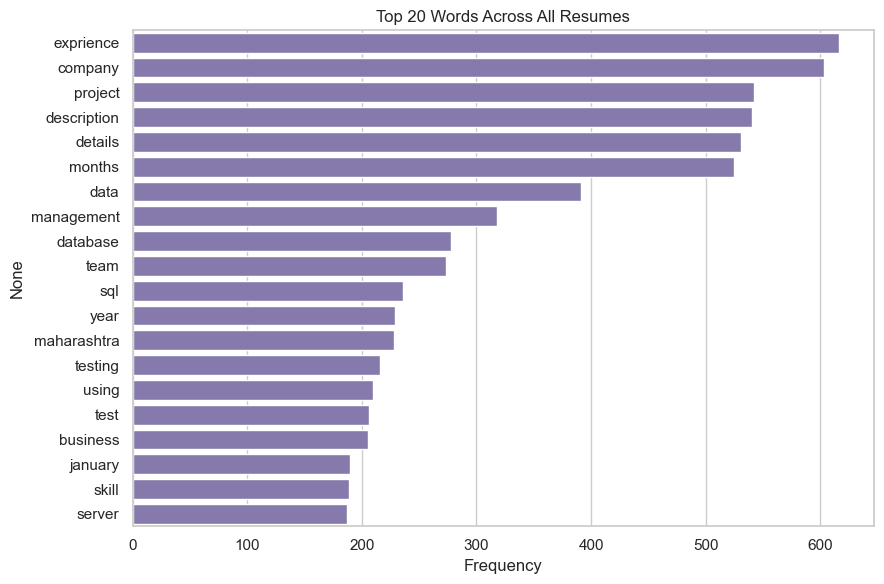

In [16]:
top_words = pd.Series(" ".join(df["Cleaned"]).split()).value_counts().head(20)
plt.figure(figsize=(9, 6))
sns.barplot(x=top_words.values, y=top_words.index, color="#8172B3")
plt.title("Top 20 Words Across All Resumes")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

## 5. Encode the labels
Convert category names into numbers so the models can use them.

In [18]:
encoder = LabelEncoder()
y = encoder.fit_transform(df["Category"])
pd.DataFrame({"Category": encoder.classes_, "Label": range(len(encoder.classes_))})

,Category,Label
0,Advocate,0
1,Arts,1
2,Automation Testing,2
3,Blockchain,3
4,Business Analyst,4
5,Civil Engineer,5
6,Data Science,6
7,Database,7
8,DevOps Engineer,8
9,DotNet Developer,9


## 6. Train/test split
80% for training, 20% for testing. **Stratified** so every category appears in both sets in the same proportion.

In [20]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["Cleaned"], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", len(X_train_text), "| Test:", len(X_test_text))

Train: 132 | Test: 34


## 7. TF-IDF feature extraction
TF-IDF turns text into numbers. Words that are common in every resume get a **low** weight; words specific to a category (e.g. *selenium*, *payroll*) get a **high** weight.

The vectorizer is fitted on the **training data only**, so no information from the test set leaks into training.

In [22]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print("TF-IDF matrix shape (train):", X_train.shape)

TF-IDF matrix shape (train): (132, 5000)


## 8. Train and compare models

In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM (Linear)": LinearSVC(),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, y_pred),
                 "Precision": p, "Recall": r, "F1-score": f1})
    print(f"Trained {name}")

results = pd.DataFrame(rows).sort_values("F1-score", ascending=False).reset_index(drop=True)
results.round(4).to_csv(IMAGES / "model_results.csv", index=False)
results.round(4)

Trained Logistic Regression
Trained SVM (Linear)
Trained Random Forest


,Model,Accuracy,Precision,Recall,F1-score
0,SVM (Linear),0.8824,0.8456,0.8824,0.8501
1,Random Forest,0.7941,0.7529,0.7941,0.7468
2,Logistic Regression,0.4706,0.3489,0.4706,0.3665


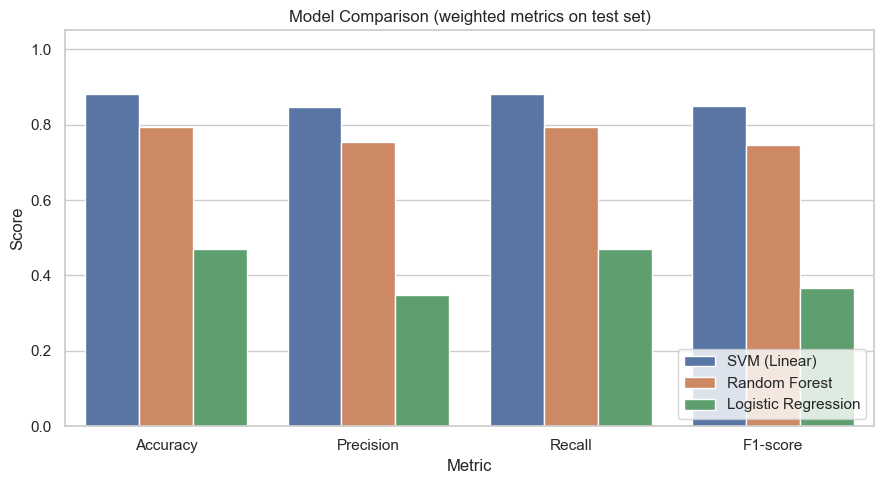

In [25]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(x="Metric", y="Score", hue="Model",
                 data=results.melt(id_vars="Model", var_name="Metric", value_name="Score"))
ax.set_ylim(0, 1.05)
plt.title("Model Comparison (weighted metrics on test set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMAGES / "model_comparison.png", dpi=120)
plt.show()

## 9. Evaluate the best model
The best model is chosen by **weighted F1-score**, which balances precision and recall across all categories.

In [51]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print("Best model:", best_name, "\n")
print(classification_report(y_test, predictions[best_name], target_names=encoder.classes_, zero_division=0))

Best model: SVM (Linear) 

                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       1.00      1.00      1.00         1
       Automation Testing       0.50      1.00      0.67         1
               Blockchain       1.00      1.00      1.00         1
         Business Analyst       0.50      1.00      0.67         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       1.00      1.00      1.00         2
                 Database       1.00      1.00      1.00         2
          DevOps Engineer       1.00      1.00      1.00         1
         DotNet Developer       1.00      1.00      1.00         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       1.00      1.00      1.00         1
                       HR       1.00      1.00      1.00         2
                   Hadoop       1.

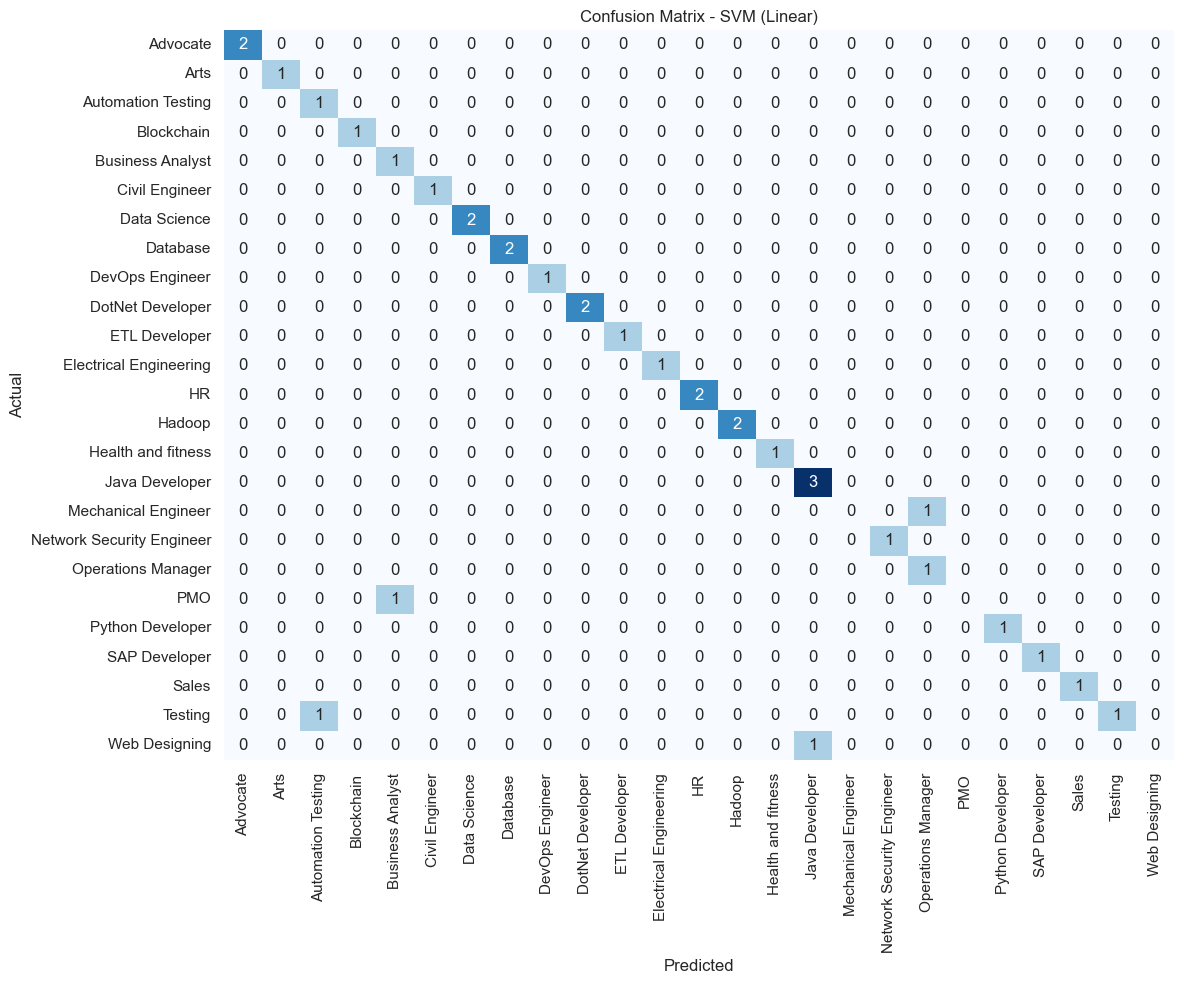

In [28]:
cm = confusion_matrix(y_test, predictions[best_name])
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(IMAGES / "confusion_matrix.png", dpi=120)
plt.show()

In [67]:
###CROSS VALIDATION

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

n_splits = min(5, df["Category"].value_counts().min())
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM (Linear)": LinearSVC(),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}.items():
    pipe = make_pipeline(TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True), model)
    s = cross_validate(pipe, df["Cleaned"], y, cv=cv, scoring=["accuracy", "f1_weighted"])
    cv_rows.append({"Model": name,
                    "CV Accuracy": s["test_accuracy"].mean(),
                    "CV F1 (weighted)": s["test_f1_weighted"].mean(),
                    "F1 std": s["test_f1_weighted"].std()})

print(f"{n_splits}-fold stratified cross-validation on {len(df)} unique resumes")
pd.DataFrame(cv_rows).round(4)

3-fold stratified cross-validation on 166 unique resumes


,Model,CV Accuracy,CV F1 (weighted),F1 std
0,Logistic Regression,0.3981,0.3073,0.0472
1,SVM (Linear),0.8739,0.8526,0.0607
2,Random Forest,0.7475,0.7088,0.0647


## 10. Save the best model

In [30]:
joblib.dump({"model": best_model, "vectorizer": vectorizer, "encoder": encoder},
            MODELS / "resume_classifier.joblib")
print("Saved to", MODELS / "resume_classifier.joblib")

Saved to models\resume_classifier.joblib


## 11. Predict the category of a new resume

In [32]:
def predict_category(resume_text):
    features = vectorizer.transform([clean_text(resume_text)])
    return encoder.inverse_transform(best_model.predict(features))[0]

samples = [
    "Wrote and executed test cases, regression testing with Selenium, logged defects in Jira",
    "Built machine learning models in Python using pandas, scikit-learn and TensorFlow",
    "Handled recruitment, onboarding, payroll and employee relations",
]
for s in samples:
    print(f"{predict_category(s):<20} <- {s}")

Automation Testing   <- Wrote and executed test cases, regression testing with Selenium, logged defects in Jira
Data Science         <- Built machine learning models in Python using pandas, scikit-learn and TensorFlow
HR                   <- Handled recruitment, onboarding, payroll and employee relations


## Conclusion
- Cleaned and vectorised resume text with **TF-IDF**, and trained **Logistic Regression, SVM and Random Forest**.
- Compared models using accuracy, precision, recall and F1-score; the best model is shown in section 9.
- **Next steps:** try more data, hyperparameter tuning with `GridSearchCV`, or word embeddings / transformer models.